# Exercise P11.1: SHAP Values & Model Limitations
### STAT 540 — Week 11


## Overview

Use SHAP values to interpret a trained model and write a comprehensive limitations section.

## Task 1: Train a Random Forest and Compute SHAP

Accuracy: 0.860
ROC AUC:  0.898


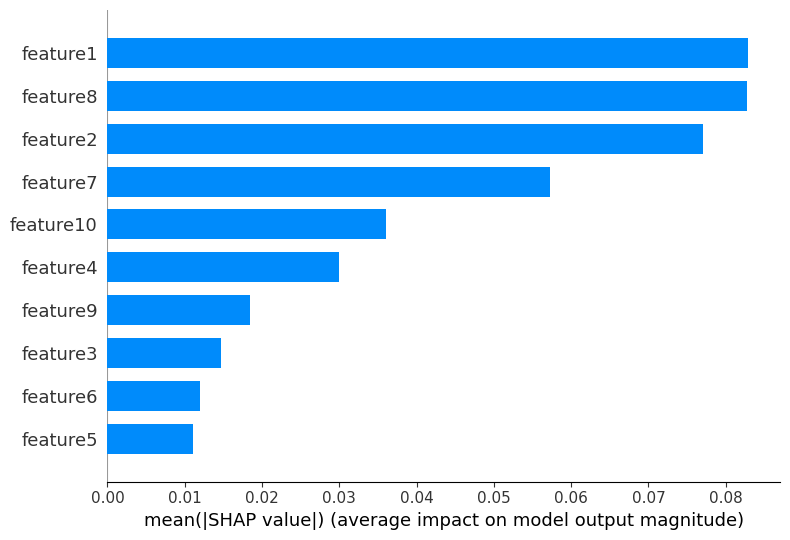

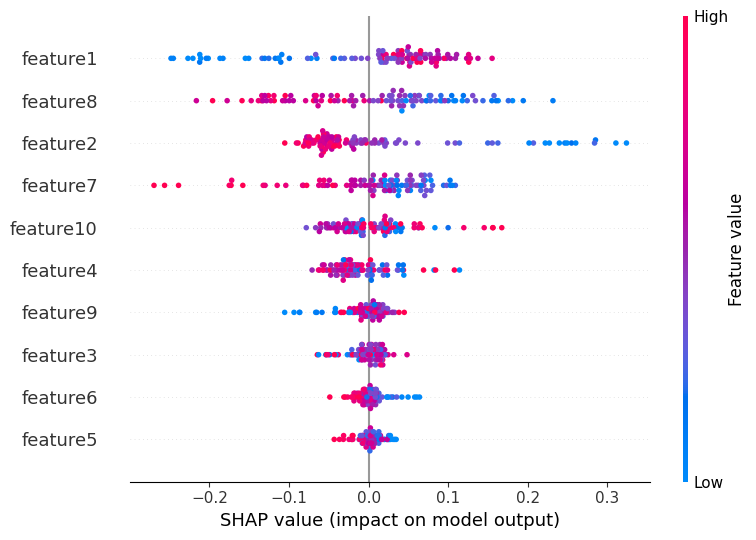

In [4]:
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

# Sanity check: is the model worth explaining?
print(f"Accuracy: {accuracy_score(y_test, model.predict(X_test)):.3f}")
print(f"ROC AUC:  {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f}")

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
sv_class1 = shap_values[1] if isinstance(shap_values, list) else shap_values[:, :, 1]

# Global importance (bar) and direction/spread (beeswarm)
shap.summary_plot(sv_class1, X_test, plot_type="bar")
shap.summary_plot(sv_class1, X_test)

**Your turn:** What are the top 3 most important features? Are you surprised?

> The top 3 features by mean shap are feature1, feature8, and feature2. Feature1 mostly pushes predictions toward class 1 when its value is high, while high values of feature8 and feature2 push predictions toward class 0. Feature2 has a long right tail, where low values produce some of the largest positive SHAP contributions (up to about +0.3). I’m only mildly surprised. The data was generated with 8 informative features, so importance is spread across many features rather than concentrated in a few. Feature7 and feature10 are close behind the top 3. The bottom features (feature5, feature6, feature3) have small impacts, as expected for the weaker or noise features. The ordering is somewhat arbitrary because the informative features get random weights in make_classification, so the specific winners aren’t meaningful beyond this dataset.

## Task 2: Partial Dependence Plots

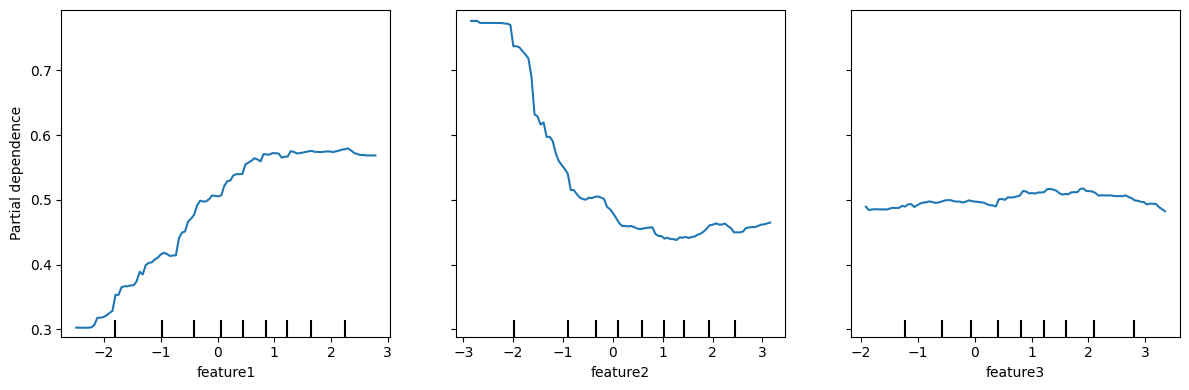

In [6]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

top_features = ["feature1", "feature2", "feature3"]  # Replace with actual names
fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(model, X_train, features=top_features, kind="average", ax=ax)
plt.tight_layout(); plt.show()

**Your turn:** Interpret each PDP in plain language — what happens to predictions as each feature increases?

> For feature 1, higher values increase the predicted probability of class 1. It rises steadily from about 0.30 at the lowest values to about 0.57 near where feature1 = 1, then plateaus. Beyond that point, further increases add little.
For feature 2, higher values decrease the predicted probability of class 1, and this is the strongest effect of the three. Probability falls from about 0.78 at the lowest values to about 0.45 by feature2 ≈ 0, with most of the drop between -2 and -1. After that it is roughly flat. This matches the SHAP plot, where low feature2 values gave the largest positive contributions.
For feature 3, there is essentially no effect. The curve stays within about 0.48 to 0.52 across its whole range, so changing feature3 barely moves the prediction. That fits its low rank in the SHAP plot.

## Task 3: "What This Model Cannot Do" (300 words)

Write a 300-word limitations section covering:

1. Data limitations
2. Distribution shift risks
3. Groups for whom predictions may be less reliable
4. What the model cannot answer (causal questions, out-of-scope uses)

> 1. Data limitations: This model was trained on 500 synthetic records, with only 400 used for training and 100 for testing. The data was generated by a computer program, not collected from real people or events, so the relationships the model learned are artificial. With so few rows, the SHAP rankings and partial dependence curves are noisy, and the ordering of mid-ranked features (such as feature2, feature7, and feature10) could easily change with a different random split. The model has also only been evaluated on one test set, so its reported accuracy may be optimistic or pessimistic by chance.

2. Distribution shift risks: The model assumes that future data looks like the training data. If it were applied to data where feature values fall outside the range seen in training, or where the relationships between features and the outcome change over time, its predictions could degrade without warning. Random forests are especially limited here, as they cannot extrapolate, so they simply repeat the nearest patterns they saw. The flat regions in the partial dependence plots show this behavior.

3. Groups with less reliable predictions: The data contains no demographic or subgroup information, so we cannot check whether the model works equally well for everyone. In a real deployment, groups that are rare in the training data would likely get less accurate predictions, because the model has fewer examples to learn from. Overall accuracy can hide poor performance for a small subgroup.

4. What the model cannot answer: The model finds associations as opposed to causes. SHAP values and partial dependence plots describe how the model behaves, not what would happen if someone changed a feature in the real world. For example, the plots show that higher feature1 values go with higher predicted probability, but this does not mean raising feature1 would cause the outcome. The model should also not be used for real decisions about people, since it was built for a teaching exercise and has not been validated for any real-world purpose.

## Submission

```bash
git add week11/exercises/P11.1*
git commit -m "Complete Exercise P11.1: SHAP interpretability and limitations"
git push origin main
```